# Forecasting Power Output (PE) Based on Ambient Environmental Conditions

- A power plant generates electricity.
- The amount of electricity it generates changes depending on environmental conditions, such as temperature, atmospheric pressure, humidity, and exhaust vacuum.

- Your task is to build a machine learning model that learns the relationship between these environmental measurements and the plant's electrical power output. 
- Once trained, the model should estimate the expected power output when given new measurements.

In [1]:
import pandas as pd
import numpy as numpy

In [2]:
df = pd.read_excel('combined+cycle+power+plant/CCPP/Folds5x2_pp.xlsx')

In [3]:
df.shape

(9568, 5)

In [4]:
df.columns

Index(['AT', 'V', 'AP', 'RH', 'PE'], dtype='object')

In [5]:
df.dtypes

AT    float64
V     float64
AP    float64
RH    float64
PE    float64
dtype: object

In [6]:
df.isna().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(41)

In [8]:
df = df.drop_duplicates().reset_index(drop = True)

In [9]:
df.duplicated().sum()

np.int64(0)

- Dataset is cleaned,no null values,no duplicates.
- All are numerical values.
- Now let's check for outliers

In [10]:
df.describe()

,AT,V,AP,RH,PE
count,9527.000000,9527.000000,9527.000000,9527.000000,9527.00000
mean,19.658225,54.293421,1013.237084,73.334951,454.33591
std,7.444397,12.686309,5.940526,14.607513,17.03908
min,1.810000,25.360000,992.890000,25.560000,420.26000
25%,13.530000,41.740000,1009.085000,63.375000,439.75000
50%,20.350000,52.080000,1012.920000,75.000000,451.52000
75%,25.710000,66.510000,1017.200000,84.850000,468.36500
max,37.110000,81.560000,1033.300000,100.160000,495.76000


<Axes: >

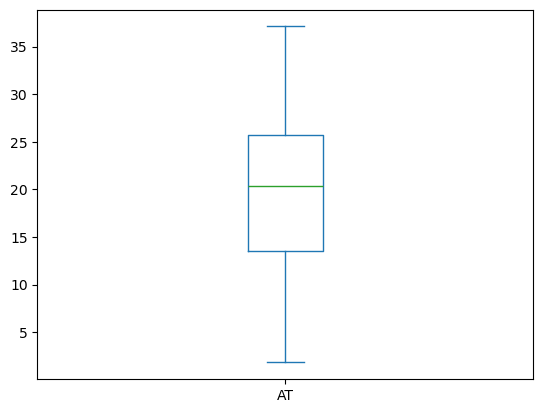

In [11]:
df['AT'].plot(kind = 'box')

<Axes: >

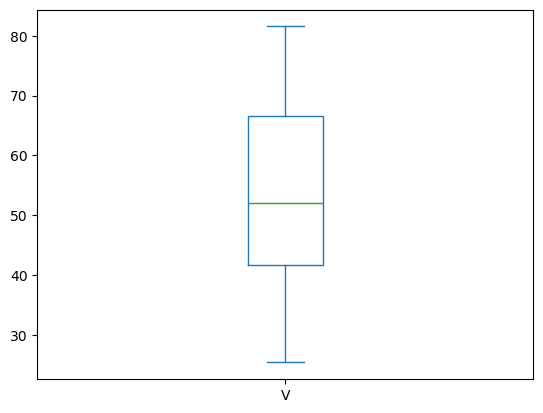

In [12]:
df['V'].plot(kind = 'box')

<Axes: >

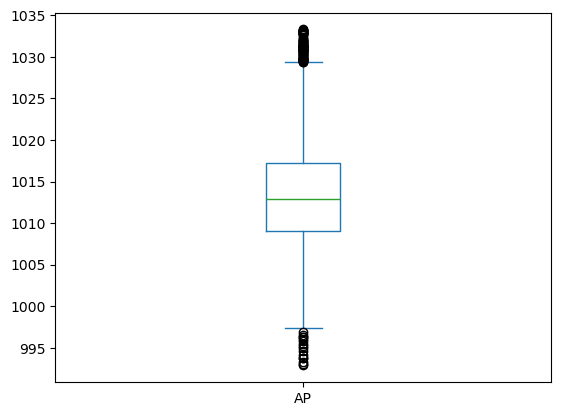

In [13]:
df['AP'].plot(kind = 'box')

<Axes: >

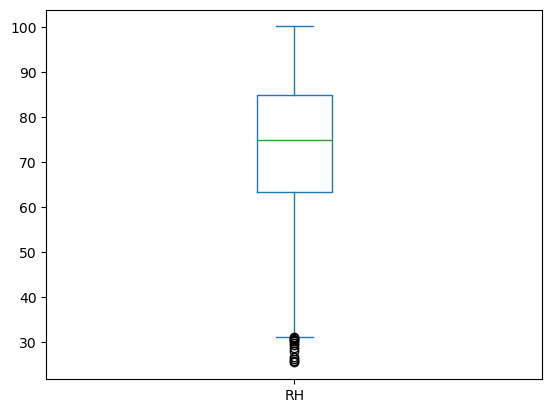

In [14]:
df['RH'].plot(kind = 'box')

<Axes: >

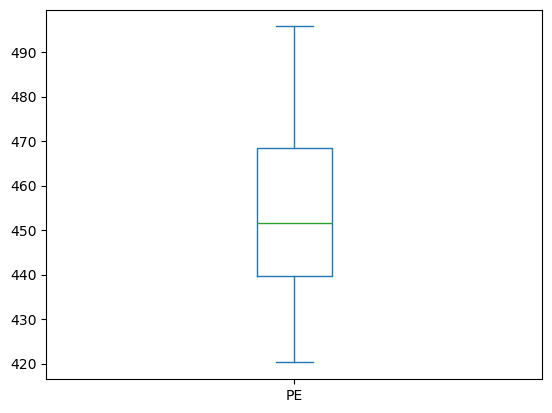

In [15]:
df['PE'].plot(kind = 'box')

- 'AP','RH' has outliers 
- lets check whether those are valid outliers or not 


In [16]:
q3 = df['AP'].quantile(0.75)
q1 = df['AP'].quantile(0.25)
IQR_AP  = q3 - q1
lower = q1 - 1.5 * IQR_AP 
upper = q3 + 1.5 * IQR_AP 
print('lower_bound value:',lower)
print('upper_bound value:',upper)
#df[df['AP'] < lower]
#df[df['AP'] > upper]

lower_bound value: 996.9125
upper_bound value: 1029.3725


In [17]:
q3 = df['RH'].quantile(0.75)
q1 = df['RH'].quantile(0.25)
IQR_RH  = q3 - q1
lower = q1 - 1.5 * IQR_RH 
upper = q3 + 1.5 * IQR_RH 
print('lower_bound value:',lower)
print('upper_bound value:',upper)
#df[df['RH'] < lower]
df[df['RH'] > upper]

lower_bound value: 31.16250000000001
upper_bound value: 117.06249999999999


,AT,V,AP,RH,PE


- if we observe every outlier is a valid outlier so we have to keep them as it is.
- No need to change anything.

## Data splitting(x,y)

In [18]:
x = df.drop(columns = 'PE')

In [19]:
x.head()

,AT,V,AP,RH
0,14.96,41.76,1024.07,73.17
1,25.18,62.96,1020.04,59.08
2,5.11,39.40,1012.16,92.14
3,20.86,57.32,1010.24,76.64
4,10.82,37.50,1009.23,96.62


In [20]:
y = df['PE']
y.head()

0    463.26
1    444.37
2    488.56
3    446.48
4    473.90
Name: PE, dtype: float64

## Train-Test split

In [21]:
import sklearn
from sklearn.model_selection import train_test_split

In [22]:
x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size = 0.2,
    random_state = 42
)


In [23]:
print('training input shape:',x_train.shape)
print('training output shape:',y_train.shape)
print()
print('testing input shape:',x_test.shape)
print('testing output shape:',y_test.shape)

training input shape: (7621, 4)
training output shape: (7621,)

testing input shape: (1906, 4)
testing output shape: (1906,)


- As we are predicting continous value for a structured dataset so we have to choose
- supervised -->regression -->  -Linear Regressor,Decision tree Regressor,KNN Regressor,Random forest regressor,SVM regressor.

- ---> Evaluation Metrics --> MAE,MSE,RMSE,R-squared.

## Model Training

In [24]:
from sklearn.metrics import root_mean_squared_error

In [25]:
#linear regression
from sklearn.linear_model import LinearRegression

In [26]:
lr = LinearRegression()
lr

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [27]:
lr.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [28]:
y_pred = lr.predict(x_test)
print(y_pred)

[462.51898394 446.67819631 447.95770234 ... 456.69453576 445.20322635
 438.03480044]


In [29]:
root_mean_squared_error(y_test,y_pred)

4.587499007655297

In [30]:
#Decision Tree Regressor
from sklearn.tree import DecisionTreeRegressor
dt = DecisionTreeRegressor()
dt.fit(x_train,y_train)
y_pred = dt.predict(x_test)
print(y_pred)
root_mean_squared_error(y_test,y_pred)

[464.95 440.94 444.05 ... 454.16 454.5  432.94]


4.720509808711852

In [31]:
#KNN Regressor
from sklearn.neighbors import KNeighborsRegressor
knn = KNeighborsRegressor()
knn.fit(x_train,y_train)
y_pred = knn.predict(x_test)
print(y_pred)
root_mean_squared_error(y_test,y_pred)

[463.932 445.374 444.804 ... 452.064 446.378 437.566]


4.0396137738356686

In [32]:
#Random forest Regressor
from sklearn.ensemble import RandomForestRegressor 
RF = RandomForestRegressor()
RF.fit(x_train,y_train)
y_pred = RF.predict(x_test)
print(y_pred)
root_mean_squared_error(y_test,y_pred)

[464.5126 443.7065 444.0136 ... 453.1217 446.5603 435.5367]


3.4307966117210755

In [33]:
# svm
from sklearn.svm import SVR
svm = SVR()
svm.fit(x_train,y_train)
y_pred = svm.predict(x_test)
print(y_pred)
root_mean_squared_error(y_test,y_pred)

[455.84474017 451.90311072 450.89876352 ... 451.52556322 450.30608786
 445.65715525]


13.438125971137291

- as Random Forest regressor have lowest RMSE value. it is calculated very nearer values so we select Random Forest Regressor.
- lets deploy the model.

# Model Deployment

In [34]:
import warnings
warnings.filterwarnings('ignore')

In [35]:
import pickle

In [36]:
#creating pickle file
with open(r'power.pkl','wb') as file:
    pickle.dump(RF,file)

In [37]:
#creating pickle files
with open(r'power.pkl','rb') as file:
    model = pickle.load(file)
model

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [38]:
def Prediction(AT,V,AP,RH):
    return model.predict([[AT,V,AP,RH]])[0]

In [39]:
#pip install gradio

In [40]:
import gradio as gr


iface = gr.Interface(fn = Prediction,
                    title = '🌄Electrical Energy Output⚡',
                    outputs = gr.Textbox(label = 'net hourly electrical energy'),
                    inputs = [
                        gr.Number(label = 'Ambient variables Temperature🔥'),
                        gr.Number(label = 'Ambient 🅿ressure'),
                        gr.Number(label = 'Relative Humidity💧'),
                        gr.Number(label = 'Exhaust Vacuum')
                    ]
                    )

In [41]:
#Launching Application


iface.launch(share = True)

In [42]:

import gradio as gr
import numpy as np

# Use your existing Prediction() function above this code.

# Solar panel image
SOLAR_IMAGE = (
    "https://images.unsplash.com/photo-1509391366360-2e959784a276"
    "?auto=format&fit=crop&w=2400&q=90"
)

css = """
/* FULL VIEWPORT BACKGROUND */
.gradio-container {
    max-width: none !important;
    width: 100% !important;
    min-height: 100vh !important;
    margin: 0 !important;
    padding: 18px 3vw 28px !important;
    box-sizing: border-box !important;

    background:
        linear-gradient(
            rgba(9, 39, 65, 0.35),
            rgba(9, 39, 65, 0.48)
        ),
        url("https://share.google/KxxEJQDUPbDVPZuaG")
        center center / cover no-repeat fixed !important;
}

/* Remove the default opaque page background */
body {
    background: #dceaf0 !important;
}

/* HEADER */
#app-header {
    background: rgba(255, 255, 255, 0.94) !important;
    border: 1px solid rgba(255,255,255,0.8);
    border-radius: 16px;
    padding: 15px 26px;
    margin-bottom: 18px;
    box-shadow: 0 6px 24px rgba(4, 29, 53, 0.13);
}

#app-header h1 {
    color: #123c70;
    font-size: 29px;
    margin: 0;
}

#app-header p {
    color: #496783;
    margin: 5px 0 0;
}

/* HERO TEXT */
#hero-copy {
    padding: 12px 10px 22px;
}

#hero-copy h2 {
    color: white;
    font-size: clamp(28px, 3.2vw, 46px);
    line-height: 1.15;
    margin: 0 0 12px;
    text-shadow: 0 2px 12px rgba(0,0,0,.35);
}

#hero-copy p {
    color: white;
    font-size: 16px;
    line-height: 1.6;
    text-shadow: 0 2px 8px rgba(0,0,0,.4);
}

/* TRANSLUCENT INPUT PANEL */
#input-panel {
    background: rgba(255, 255, 255, 0.94) !important;
    border: 1px solid rgba(255,255,255,0.95) !important;
    border-radius: 20px !important;
    padding: 22px !important;
    box-shadow: 0 12px 35px rgba(4, 29, 53, 0.22);
}

#input-panel h2,
#input-panel h3 {
    color: #123b70 !important;
}

/* INPUTS */
.input-card {
    background: rgba(242, 249, 255, 0.96) !important;
    border: 1px solid #d6e7f5 !important;
    border-radius: 13px !important;
    padding: 12px !important;
}

.input-card label {
    color: #173e6d !important;
    font-weight: 600 !important;
}

.input-card input {
    background: white !important;
    color: #173e6d !important;
    border: 1px solid #cbddeb !important;
    border-radius: 9px !important;
    min-height: 42px !important;
}

/* PREDICTION BUTTON */
#predict-btn {
    background: linear-gradient(100deg, #2176f5, #16bfa5) !important;
    color: white !important;
    border: none !important;
    border-radius: 12px !important;
    min-height: 54px !important;
    font-size: 17px !important;
    font-weight: 700 !important;
    margin-top: 14px !important;
    box-shadow: 0 5px 15px rgba(15, 145, 176, 0.20);
}

#predict-btn:hover {
    filter: brightness(1.08);
}

/* BOTTOM OUTPUT BOX */
#result-panel {
    background: rgba(245, 255, 251, 0.97) !important;
    border: 2px solid #25c7a4 !important;
    border-radius: 19px !important;
    padding: 22px !important;
    margin-top: 18px !important;
    box-shadow: 0 9px 28px rgba(4, 29, 53, 0.20);
}

#result-panel h2 {
    color: #123b70 !important;
}

#prediction-output textarea {
    background: #f0fff9 !important;
    color: #079879 !important;
    font-size: 27px !important;
    font-weight: 700 !important;
    border: 1px solid #a6e7d5 !important;
    border-radius: 12px !important;
    min-height: 65px !important;
}

/* FOOTER */
#project-footer {
    text-align: center;
    color: white;
    text-shadow: 0 1px 5px rgba(0,0,0,.65);
    font-size: 13px;
    padding: 18px 0 0;
}

footer {
    display: none !important;
}

/* SMALL SCREENS */
@media (max-width: 700px) {
    .gradio-container {
        padding: 10px !important;
    }

    #app-header {
        padding: 14px;
    }

    #input-panel,
    #result-panel {
        padding: 15px !important;
    }
}
"""


def predict_output(temperature, pressure, humidity, vacuum):
    values = [temperature, pressure, humidity, vacuum]

    if any(value is None for value in values):
        return "Please enter all four measurements."

    if not all(np.isfinite(value) for value in values):
        return "Enter valid numerical measurements."

    # Keep the feature order consistent with model training.
    result = Prediction(
        temperature,
        pressure,
        humidity,
        vacuum
    )

    if isinstance(result, (list, tuple, np.ndarray)):
        result = np.asarray(result).reshape(-1)[0]

    if hasattr(result, "item"):
        result = result.item()

    try:
        return f"{float(result):,.2f} MW"
    except (TypeError, ValueError):
        return str(result)


with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="blue",
        secondary_hue="emerald",
        neutral_hue="slate"
    ),
    css=css,
    title="PowerPlantIQ | Power Prediction",
    fill_width=True
) as demo:

    gr.HTML("""
    <div id="app-header">
        <h1>⚡ PowerPlant<span style="color:#16bfa5">IQ</span></h1>
        <p>Combined Cycle Power Plant Analytics</p>
    </div>
    """)

    gr.HTML("""
    <div id="hero-copy">
        <h2>
            Predicting Power,<br>
            <span style="color:#64f1d2">
                Building a Smarter Tomorrow
            </span>
        </h2>
        <p>
            Estimate net electrical power output from four environmental
            measurements using machine learning.
            <br>
            ⚡ 4 Input Features &nbsp; • &nbsp;
            📊 9,568 Observations &nbsp; • &nbsp;
            🌱 Energy Analytics
        </p>
    </div>
    """)

    # Input holders over the solar background
    with gr.Group(elem_id="input-panel"):
        gr.Markdown("## ⚙️ Enter Operating Conditions")
        gr.Markdown(
            "Provide the four measurements to estimate the power output."
        )

        with gr.Row():
            temperature = gr.Number(
                label="🌡️ Ambient Temperature (°C)",
                value=25.0,
                elem_classes=["input-card"]
            )

            pressure = gr.Number(
                label="🌬️ Ambient Pressure (mbar)",
                value=1013.0,
                elem_classes=["input-card"]
            )

        with gr.Row():
            humidity = gr.Number(
                label="💧 Relative Humidity (%)",
                value=60.0,
                elem_classes=["input-card"]
            )

            vacuum = gr.Number(
                label="🔧 Exhaust Vacuum (cm Hg)",
                value=50.0,
                elem_classes=["input-card"]
            )

        predict_btn = gr.Button(
            "⚡ Predict Power Output",
            elem_id="predict-btn",
            variant="primary"
        )

    # Separate bordered output box at the bottom
    with gr.Group(elem_id="result-panel"):
        gr.Markdown("## ⚡ Predicted Net Electrical Power Output")

        prediction_output = gr.Textbox(
            label="Estimated output",
            placeholder="Your prediction will appear here in MW",
            interactive=False,
            elem_id="prediction-output",
            lines=1
        )

        gr.Markdown(
            "Model estimate based on the entered conditions. "
            "This is not a live plant measurement."
        )

    predict_btn.click(
        fn=predict_output,
        inputs=[
            temperature,
            pressure,
            humidity,
            vacuum
        ],
        outputs=prediction_output
    )

    gr.HTML("""
    <div id="project-footer">
        PowerPlantIQ · Machine Learning Portfolio Project
        <br>
        Dataset: UCI Combined Cycle Power Plant (2006–2011)
    </div>
    """)


if __name__ == "__main__":
    demo.launch(share=True)


* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://2a8d788fda9b7e12c4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
